# Exploración del espacio de diseño de un Cortex-A76 con gem5 y McPAT

**Autor:** Luis Andres Castillo · **Aplicación analizada:** `mp3_enc` · **Versión:** 1.0 · octubre de 2026

## Resumen

Se estudia cómo influyen los parámetros microarquitectónicos de un procesador Cortex-A76 en su rendimiento (CPI) y en su energía,
con el simulador gem5 y el modelo de potencia McPAT. Tras 40 simulaciones manuales que acotaron el espacio a 23 328 combinaciones,
un algoritmo genético multiobjetivo (NSGA-II) evaluó 1004 configuraciones distintas; una búsqueda aleatoria de 300 evaluaciones sirvió de control.
La mejor configuración según el producto energía-retardo (EDP) reduce el EDP un 26 % respecto al A76 por defecto, con un CPI 18 % menor y una energía 9,5 % menor.
Casi toda la mejora proviene de ampliar la cola de instrucciones (IQ) de 16 a 48–64 entradas. El NSGA-II supera a la búsqueda aleatoria por poco en el mejor punto.

## 1. Introducción

### 1.1 Objetivo y método
El objetivo es cuantificar el efecto de los parámetros microarquitectónicos de un Cortex-A76 sobre rendimiento y energía, y encontrar los mejores compromisos.
El método consta de cuatro pasos: (1) perfilar la aplicación, (2) realizar simulaciones manuales para identificar los parámetros relevantes,
(3) definir un espacio de diseño (DSE) y explorarlo con una estrategia automatizada, y (4) analizar los resultados con las métricas descritas a continuación.

### 1.2 Métricas
Con *Leakage* y *Dynamic* tomados de McPAT y el CPI de gem5 (`system.cpu.cpi`), se definen:

$$\text{Energía} = (\text{Total Leakage} + \text{Runtime Dynamic}) \cdot \text{CPI} \qquad\qquad \text{EDP} = \text{Energía} \cdot \text{CPI}$$

Menor es mejor en las tres métricas (CPI, energía y EDP). El CPI (ciclos por instrucción) es el inverso del IPC [5]. La "energía" es potencia × CPI, no julios: a frecuencia fija sirve para comparar configuraciones entre sí.


### 1.2.1 Dominancia y frente de Pareto
Como el CPI y la energía se quieren minimizar, una configuración **A domina a B** si es igual o mejor en ambos objetivos y estrictamente mejor en al menos uno. En ese caso, B se descarta porque A ofrece un resultado igual o superior en todo.

El **frente de Pareto** reúne las configuraciones que ninguna otra domina. Entre ellas existe un compromiso: algunas tienen mejor rendimiento (menor CPI) pero consumen más energía; otras consumen menos pero rinden peor. Por eso no existe un único óptimo y la exploración busca el frente completo (estrategia en la sección 6).

A partir del frente se seleccionan tres configuraciones de interés: la de menor CPI, la de menor energía y la de menor EDP, que combina energía y CPI para evaluar el equilibrio entre ambos objetivos.

### 1.3 Contenido del informe

**Tabla 1.** Contenido del informe y sección donde se encuentra.

| Contenido | Sección |
|---|---|
| Perfil de la aplicación | 3, Figura 1 |
| Descripción de los parámetros modificados | 5, Tabla 6 |
| Rendimiento frente a recursos (gráficas y análisis) | 4, Figuras 2 y 3 |
| Plano 2D rendimiento–energía con todos los puntos simulados | 8.2, Figura 4 |
| Relación del EDP con CPI y energía, evolución de la exploración, efecto de cada parámetro y distribución estadística del EDP | 8.3 a 8.5, Figuras 5 a 8 |
| Las tres mejores configuraciones (rendimiento, energía y EDP) | 9, Tabla 11 |
| Velocidad de gem5 y McPAT: una simulación y total de la exploración | 10, Tabla 13 |
| Conclusiones | 11 |
| Ubicación de todos los resultados y datos crudos | 12 |
| Referencias | 13 |
| Scripts de simulaciones y de procesamiento de resultados | 7 (`sim.sh`, `dse.py`) |
| Exploración de más de mil simulaciones | 5 y 8.1 (1004 con NSGA-II; 1330 en total) |
| Estrategia de exploración más eficiente que la fuerza bruta | 6 y 8.6 |
| Cálculo de energía y EDP | 1.2 y 8.1 |
| Repositorio git | 12 |

### 1.4 Cronología: fases hasta el lanzamiento del DSE

El trabajo se hizo en cinco fases.

| Fase | Qué se hizo | Por qué | Resultado y decisión |
|---|---|---|---|
| **0. Entorno y línea base** | Montaje de gem5 v25.0.0.1 y McPAT en Ubuntu (WSL2). Simulación de la configuración por defecto del A76 (`sim1`). Medición de tiempos y de simulaciones en paralelo | Comprobar que el flujo gem5 → conversor → McPAT funciona y es reproducible, y estimar cuántas simulaciones caben en el tiempo disponible | CPI de la línea base = 1,045577. Una simulación tarda ≈ 617 s (gem5 593 s, McPAT 21 s); con 6 en paralelo salen ≈ 29 simulaciones por hora.|
| **1. Perfil y variaciones de un parámetro** | Perfil de `mp3_enc` (mezcla de instrucciones, ocupación de unidades funcionales, fallos de caché) y 19 simulaciones que cambian un parámetro cada vez (IQ, ROB, colas, puertos, predictor) | Saber qué limita el rendimiento y qué parámetros conviene explorar | La IQ por defecto es el cuello de botella y se satura cerca de 64 entradas.|
| **2. Cachés, anchos e IQ alrededor de 64** | 22 simulaciones más con IQ = 64: tamaños de L1 y L2, ancho del pipeline, `issue_width`, `dispatch_width` y `wb_width` | Fijar los rangos del espacio de diseño a explorar| Las cachés casi no cambian el CPI y solo cuestan potencia y área; ancho 4 es el punto correcto; `dispatch_width` y `wb_width` no tienen efecto. Se acotan los valores y quedan **23 328 combinaciones** |
| **3. Motor paralelo (`dse.py`)** | Escritura del motor: simulaciones en paralelo, `results.csv`. Pruebas con PC personal para validar simulaciones reales | Poder lanzar más de mil simulaciones sin supervisión y sin repetir ninguna | El motor funciona. La estación de trabajo da un CPI ≈ 0,01–0,04 % distinto del PC de las pruebas manuales, así que **todo el DSE se ejecuta en un solo equipo** |
| **4. Exploración** | NSGA-II con las semillas de las fases 1 y 2 (1004 simulaciones, ≈ 34 h) y una búsqueda aleatoria de control (300 evaluaciones, ≈ 9,7 h) | Encontrar el frente de Pareto con mucho menos cómputo que la fuerza bruta y medir cuánto aporta el algoritmo | Resultados en las secciones 8 a 10 |

Las 40 simulaciones manuales (fases 0 a 2) fueron el inicio para fijar parámetros, rangos y semillas con las que explorar (sección 4.1).


## 2. Entorno experimental

**Tabla 2.** Herramientas y máquinas.

| Elemento | Detalle |
|---|---|
| Simulador | gem5 v25.0.0.1 [1], ARM|
| Modelo de potencia | McPAT [2], con el flujo: `stats.txt` + `config.json` + plantilla XML → `config.xml` → McPAT |
| Procesador | Cortex-A76 (script de gem5 `CortexA76.py` y plantilla de McPAT `ARM_A76_2.1GHz.xml`) |
| Aplicación | `mp3_enc`, entrada `mp3enc_testfile.wav` (98 kB), 241 423 320 instrucciones confirmadas |
| Máquina del DSE | Estación de trabajo del laboratorio LED (Universidad de Antioquia): Intel Xeon W-2135 a 3,7 GHz, 6 núcleos / 12 hilos, 31 GiB de RAM, Ubuntu |
| Máquina de las pruebas manuales | PC personal (Ubuntu sobre WSL2) |
| Optimización | `pymoo` 0.6 [4] (NSGA-II [3]) |

**Reproducibilidad.** Todas las simulaciones se lanzan de una sola forma (rutas absolutas y `--cwd`, función `sim` de la sección 7). La misma configuración da el mismo resultado exacto en la misma máquina.
Entre las dos máquinas el CPI de una misma configuración difiere entre 0,010 % y 0,036 % ( Por ello la configuración por defecto
(`sim1`) se midió en el PC personal y el DSE en la estación de trabajo; la diferencia es despreciable.

**Archivos del repositorio que usa el notebook** (todos en la misma carpeta que este archivo):

| Archivo | Contenido |
|---|---|
| `results/results.csv` | 1330 simulaciones: 40 manuales, 1004 NSGA-II y 286 aleatorias |
| `results/random_log.csv` | Las 300 evaluaciones aleatorias, en orden |
| `config/espacio.csv`, `config/semillas.csv` | Espacio de diseño y semillas del NSGA-II |
| `config/manuales.txt` | Las simulaciones manuales, una por línea (41 líneas; una repetida se omite al importar, quedan 40). `dse.py import` las carga |
| `scripts/sim.sh`, `scripts/gem5toMcPAT_cortexA76.py`, `dse.py` | Simulación manual, conversor gem5 → McPAT y motor del DSE (sección 7) |
| `figuras/` | Figuras generadas por este notebook |

Con `RUN_SIMS = False` el notebook solo analiza los resultados guardados; con `True` puede relanzar simulaciones reales (sección 7).

In [1]:
from pathlib import Path
import sys, subprocess
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

RUN_SIMS = False # False: solo analiza results/. True: lanza simulaciones reales (requiere gem5 y McPAT).
DATA = Path("results")

# Formato de gráficas
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
AZUL, NARANJA, VERDE, ROJO, NEGRO = "#0072B2", "#E69F00", "#009E73", "#D55E00", "#222222"

In [2]:
# Carga de resultados
KEYS = ["iq_entries", "width", "rob_entries", "lq_entries", "sq_entries", "l1i_kb", "l1d_kb", "l2_kb", "issue_width"]

todo   = pd.read_csv(DATA / "results.csv")
orden  = pd.read_csv(DATA / "random_log.csv")
manual = todo[todo.source == "manual"] # simulaciones manuales
nsga   = todo[todo.source == "nsga"].sort_values("eval_idx").reset_index(drop=True)
unicas = todo[todo.source != "manual"].drop_duplicates("hash").set_index("hash")
aleat  = unicas.loc[orden.hash].reset_index() # las 300 evaluaciones aleatorias, en orden
BASE   = manual[manual.name == "sim1"].iloc[0] # A76 por defecto
IQ64   = manual[manual.name == "iq64"].iloc[0] # base de los experimentos con IQ = 64

def pareto(df):
    # Puntos no dominados en (CPI, energía): ningún otro punto es mejor en ambos.
    P = df[["cpi", "energy"]].values
    mejor = [not ((P[:, 0] <= c) & (P[:, 1] <= e) & ((P[:, 0] < c) | (P[:, 1] < e))).any() for c, e in P]
    return df[mejor]

def hipervolumen(df, ref):
    # Área dominada por el frente respecto a un punto de referencia (mayor = mejor frente).
    f = pareto(df).sort_values("cpi")
    area, e_prev = 0.0, ref[1]
    for c, e in zip(f.cpi, f.energy):
        area += (ref[0] - c) * (e_prev - e); e_prev = e
    return area

print(todo.source.value_counts().to_dict(), "| evaluaciones aleatorias:", len(aleat))

{'nsga': 1004, 'random': 286, 'manual': 40} | evaluaciones aleatorias: 300


## 3. Perfil de la aplicación

Se obtuvo de `stats.txt` de la simulación por defecto (`sim1`): tipos de instrucción confirmadas (`committedInstType`), tasas de fallo de caché y ocupación de unidades funcionales.

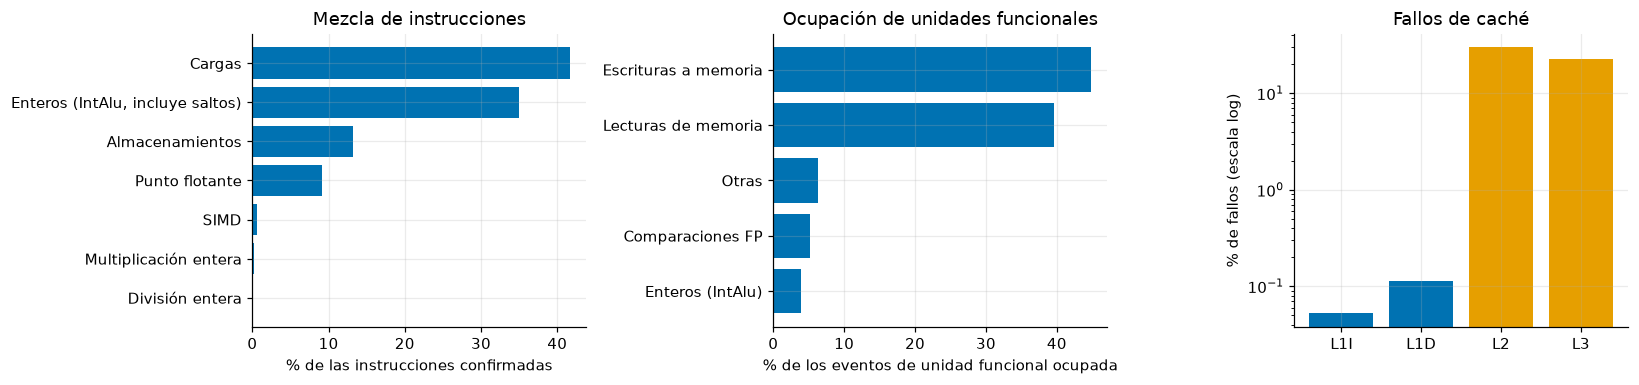

In [123]:
# Perfil de sim1: se lee de las estadísticas de gem5 (sim1/stats.txt)
st = {}
for linea in (DATA / "sim1/stats.txt").read_text().splitlines():
    p = linea.split()
    if linea.startswith("system.") and len(p) > 1:
        st[p[0]] = float(p[1])

def por_clase(prefijo):
    return {k.split("::")[1]: v for k, v in st.items() if k.startswith(prefijo + "::") and not k.endswith("::total")}

tipos = por_clase("system.cpu.commitStats0.committedInstType")
total = st["system.cpu.commitStats0.committedInstType::total"]
pct   = lambda v, t: 100 * v / t
mezcla = pd.Series({
    "Cargas":                           pct(tipos["MemRead"], total),
    "Almacenamientos":                  pct(tipos["MemWrite"], total),
    "Enteros (IntAlu, incluye saltos)": pct(tipos["IntAlu"], total),
    "Punto flotante":                   pct(sum(v for k, v in tipos.items() if k.startswith("Float") and "Mem" not in k), total),
    "SIMD":                             pct(sum(v for k, v in tipos.items() if k.startswith("Simd")), total),
    "Multiplicación entera":            pct(tipos["IntMult"], total),
    "División entera":                  pct(tipos["IntDiv"], total),
}).sort_values()

fallos = pd.Series({"L1I": st["system.cpu.icache.demandMissRate::total"], "L1D": st["system.cpu.dcache.demandMissRate::total"],
                    "L2": st["system.cpu.l2cache.demandMissRate::total"], "L3": st["system.l3cache.demandMissRate::total"]}) * 100

busy = por_clase("system.cpu.statFuBusy")
principales = {"Escrituras a memoria": "MemWrite", "Lecturas de memoria": "MemRead", "Comparaciones FP": "FloatCmp", "Enteros (IntAlu)": "IntAlu"}
ocupacion = pd.Series({n: pct(busy[c], sum(busy.values())) for n, c in principales.items()})
ocupacion["Otras"] = 100 - ocupacion.sum()
ocupacion = ocupacion.sort_values()

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].barh(mezcla.index, mezcla.values, color=AZUL); ax[0].set_xlabel("% de las instrucciones confirmadas"); ax[0].set_title("Mezcla de instrucciones")
ax[1].barh(ocupacion.index, ocupacion.values, color=AZUL); ax[1].set_xlabel("% de los eventos de unidad funcional ocupada"); ax[1].set_title("Ocupación de unidades funcionales")
ax[2].bar(fallos.index, fallos.values, color=[AZUL, AZUL, NARANJA, NARANJA]); ax[2].set_yscale("log"); ax[2].set_ylabel("% de fallos (escala log)"); ax[2].set_title("Fallos de caché")
plt.tight_layout(); plt.savefig("figuras/fig1_perfil.png", dpi=150); plt.show()

**Figura 1.** Perfil de `mp3_enc` con la configuración por defecto: mezcla de instrucciones (izquierda), unidades funcionales que se encuentran ocupadas (centro; en total el 3,02 % de las instrucciones) y tasa de fallos de caché (derecha).

**Tabla 3.** Resumen del perfil.

| Aspecto | Valor | Interpretación |
|---|---|---|
| Accesos a memoria | 54,9 % (41,70 % cargas + 13,17 % almacenamientos) | Código dominado por memoria |
| Punto flotante | ≈ 9,2 %; SIMD 0,66 % | Punto flotante escalar, casi sin código vectorial |
| Fallos de L1 | L1I 0,0525 %; L1D 0,113 % | Las L1 casi nunca fallan |
| Fallos de L2 y L3 | 29,98 % y 22,74 % | Altos, pero sobre muy pocos accesos |
| Unidades funcionales ocupadas | 3,02 % de las instrucciones; 84,4 % son puertos de memoria | Poco limitante |
| Predictor de saltos | 16,95 % de las consultas terminan en *squash* | 4,58 % de lo emitido se descarta |

**Análisis.** El conjunto de trabajo cabe en las cachés L1, por lo que la jerarquía de memoria no limita el rendimiento. El cuello de botella está en el núcleo fuera de orden (ventana de instrucciones y predictor de saltos).
Por esa razón los experimentos manuales se centraron primero en los parámetros del núcleo, y las cachés se trataron principalmente como un factor de costo.

## 4. Exploración manual

### 4.1 Simulaciones manuales: qué se hizo y para qué sirvieron
Antes de automatizar se realizaron 40 simulaciones manuales (variaciones de un parámetro, combinaciones con IQ = 64, cachés, anchos y `issue_width`), lanzadas con `sim.sh` y registradas en `config/manuales.txt`.
Estas cumplieron cinco funciones:

1. **Validar el flujo** gem5 → conversor → McPAT, comprobando que el resultado es reproducible.
2. **Saber qué parámetros mueven el rendimiento** y cuáles no (la IQ lo domina; los puertos de memoria, el ROB y las colas casi no lo cambian con la IQ por defecto).
3. **Descubrir qué parámetros ve McPAT** (Tabla 5), lo que decide cuáles pueden entrar al DSE.
4. **Definir rangos acotads:** reducir el espacio de valores (IQ de 8 a 128 entradas, ROB hasta 256, L2 hasta 4 MB…) a 23 328 combinaciones útiles.
5. **Aportar las semillas** con las que arranca el algoritmo evolutivo.

La Tabla 4 resume las más representativas (Δ respecto a la configuración por defecto `sim1`).

In [4]:
clave = ["sim1", "iq8", "iq32", "f2_iq48", "iq64", "f2_iq96", "iq128", "ancho2", "f2_ancho3", "f2_ancho5", "rob64", "rob256",
         "f2_issue3", "f2_issue4", "f2_issue6", "f2_l1i32", "f2_l1d32", "f2_l2_512k", "f2_l2_2m", "bp_tage"]
t = manual.set_index("name").loc[clave, KEYS + ["cpi", "power_w", "energy", "edp", "area_mm2"]].copy()
t["ΔCPI %"] = 100 * (t.cpi / BASE.cpi - 1)
t["ΔEDP %"] = 100 * (t.edp / BASE.edp - 1)
t.round(4)

,iq_entries,width,rob_entries,lq_entries,sq_entries,l1i_kb,l1d_kb,l2_kb,issue_width,cpi,power_w,energy,edp,area_mm2,ΔCPI %,ΔEDP %
name,,,,,,,,,,,,,,,,
sim1,16,4,128,68,72,64,64,256,8,1.0456,2.1680,2.2668,2.3701,35.5383,0.0000,0.0000
iq8,8,4,128,68,72,64,64,256,8,1.4282,1.8204,2.5999,3.7132,35.5383,36.5965,56.6686
iq32,32,4,128,68,72,64,64,256,8,0.8646,2.4600,2.1269,1.8389,35.5389,-17.3092,-22.4144
f2_iq48,48,4,128,68,72,64,64,256,8,0.8505,2.5046,2.1302,1.8117,35.5403,-18.6572,-23.5612
iq64,64,4,128,68,72,64,64,256,8,0.8470,2.5208,2.1352,1.8085,35.5415,-18.9915,-23.6957
f2_iq96,96,4,128,68,72,64,64,256,8,0.8472,2.5366,2.1490,1.8206,35.6012,-18.9743,-23.1856
iq128,128,4,128,68,72,64,64,256,8,0.8472,2.5515,2.1616,1.8313,35.6641,-18.9730,-22.7338
ancho2,16,2,128,68,72,64,64,256,8,1.0921,2.0775,2.2689,2.4780,35.5238,4.4528,4.5500
f2_ancho3,64,3,128,68,72,64,64,256,8,0.9571,2.2841,2.1861,2.0922,35.5334,-8.4646,-11.7247


**Tabla 4.** Simulaciones manuales representativas.

**Qué parámetros llegan a McPAT.** McPAT no lee la configuración de gem5 directamente: solo lee `config.xml`, un archivo de texto que el conversor `gem5toMcPAT_cortexA76.py` genera para cada simulación a partir de `config.json` y `stats.txt`. Todo parámetro que no llegue a ese archivo no se refleja en la potencia ni en el área.

Para saber cuáles llegan, se comparó el `config.xml` de cada variante con el de la base usando `diff`, que muestra solo las líneas que difieren entre dos archivos. Se filtraron las líneas `<param>` (la estructura) para ignorar las `<stat>`, que cambian en cualquier simulación:

```bash
diff base/config.xml variante/config.xml | grep "<param"
```

- Si el comando **muestra líneas**, el parámetro cambió en el XML: McPAT **lo ve** y lo cobra en potencia o área.
- Si el comando **no muestra nada**, los dos XML son iguales: McPAT **no lo ve**. Aunque el parámetro cambie el CPI en gem5, su costo no aparece en la energía.

**Tabla 5.** Visibilidad de los parámetros en McPAT.

| Parámetro de gem5 | ¿Lo ve McPAT? | Consecuencia |
|---|---|---|
| `rob_entries`, `lq_entries`, `sq_entries` | Sí | Influye en potencia y área |
| `iq_entries` | Sí | Desplaza la curva de potencia |
| Ancho de fetch/decode/commit, `issue_width`, tamaños de caché | Sí | Influyen |
| Puertos de unidades funcionales, predictor de saltos | **No** | Serían "gratis": se dejan fijos |
| `dispatch_width`, `wb_width` | **No** (y no cambian el CPI) | Se dejan fijos |


### 4.2 Rendimiento frente a recursos
Cada curva cambia **un** parámetro y mantiene el resto en la base. Para la IQ la base es el A76 por defecto; para los demás parámetros es la configuración con IQ = 64.

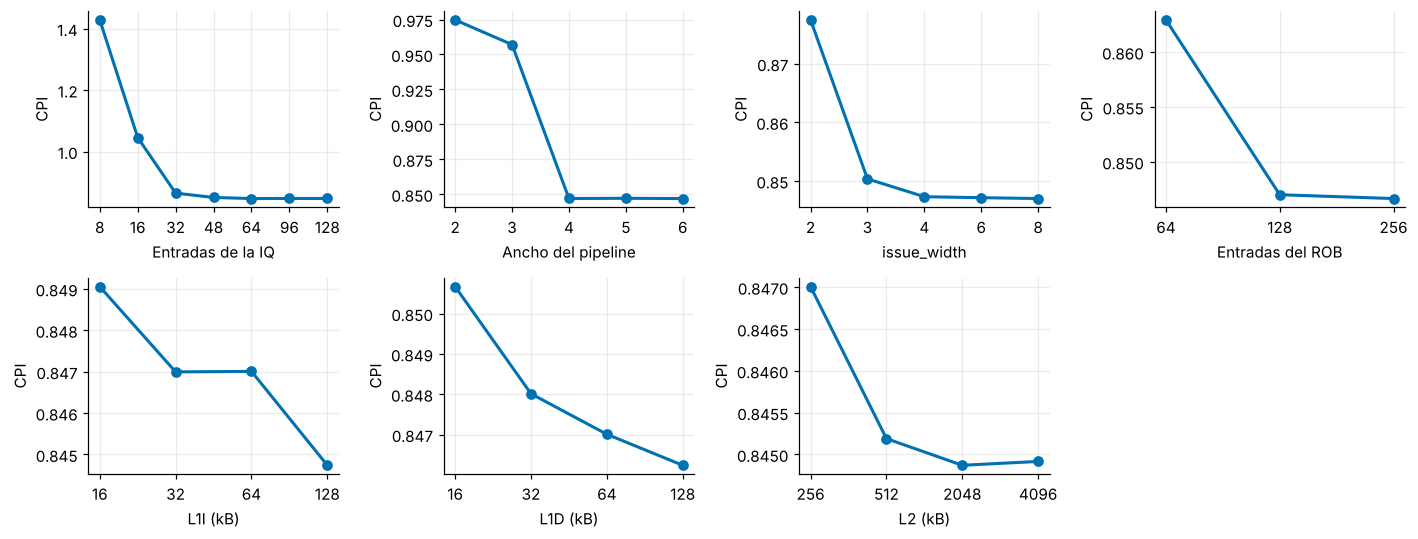

In [5]:
PARAMETROS = [("iq_entries", BASE, "Entradas de la IQ"), ("width", IQ64, "Ancho del pipeline"), ("issue_width", IQ64, "issue_width"),
              ("rob_entries", IQ64, "Entradas del ROB"), ("l1i_kb", IQ64, "L1I (kB)"), ("l1d_kb", IQ64, "L1D (kB)"), ("l2_kb", IQ64, "L2 (kB)")]

def barrido(param, base):
    # Simulaciones manuales (sin opciones extra) donde solo cambia `param` respecto a `base`.
    t = manual[manual.extras.isna()]
    for k in KEYS:
        if k != param:
            t = t[t[k] == base[k]]
    return t.sort_values(param)

def graficar(metrica, etiqueta, archivo):
    fig, axs = plt.subplots(2, 4, figsize=(13, 5)); axs = axs.ravel()
    for ax, (param, base, titulo) in zip(axs, PARAMETROS):
        t = barrido(param, base)
        ax.plot(t[param].astype(str), t[metrica], "o-", color=AZUL, lw=2)
        ax.set_xlabel(titulo); ax.set_ylabel(etiqueta)
    axs[-1].axis("off")
    plt.tight_layout(); plt.savefig(archivo, dpi=150); plt.show()

graficar("cpi", "CPI", "figuras/fig2_cpi_vs_recursos.png")

**Figura 2.** CPI frente a cada recurso (menor es mejor).

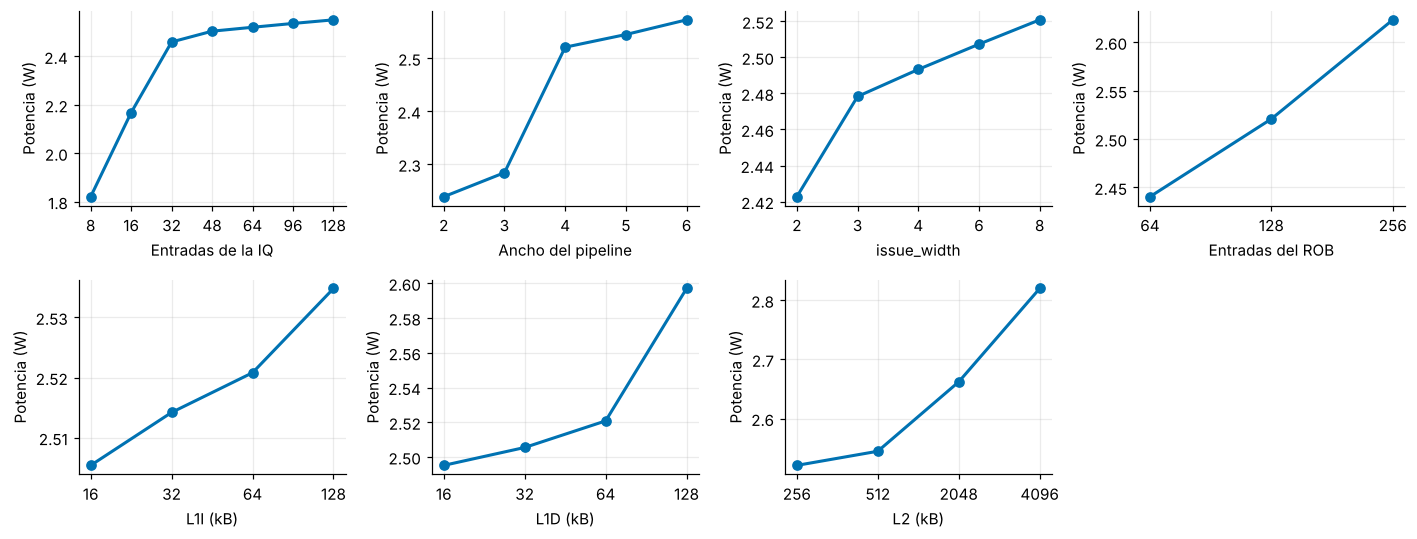

In [6]:
graficar("power_w", "Potencia (W)", "figuras/fig3_potencia_vs_recursos.png")

**Figura 3.** Potencia estimada por McPAT frente a cada recurso.

**Análisis.**
1. **La IQ domina.** Con la IQ por defecto (16 entradas) casi ningún otro parámetro mueve el CPI. Subirla a 64 reduce el CPI un 19 % y el EDP un 23,7 %; la mejora se satura entre 48 y 64, y a partir de ahí solo crece la potencia. Reducirla a 8 empeora el EDP un 56,7 %.
2. **Ancho 4 es el punto correcto.** El ancho 3 cuesta un 13 % de CPI; los anchos 5 y 6 no mejoran el CPI y solo suman potencia.
3. **`issue_width` sobra en 8.** Bajarlo a 3 o 4 casi no cambia el CPI (+0,40 % y +0,04 %) y reduce potencia y área, porque el pipeline es de ancho 4.
4. **Las cachés casi no cambian el CPI** (menos de 0,5 %) pero sí la potencia y el área: una L2 de 2 MB cuesta +7,8 % de área por −0,25 % de CPI.
5. **Los parámetros interactúan.** El ancho 2 cuesta +4,5 % de CPI con IQ = 16 y +15 % con IQ = 64; por eso no basta con variarlos de uno en uno y se justifica una búsqueda multiobjetivo.

## 5. Definición del espacio de diseño (DSE)

El espacio no está escrito dentro de `dse.py`: se lee de `config/espacio.csv` (parámetro, valor por defecto del A76, valores a explorar y comentario) y las semillas del NSGA-II de `config/semillas.csv`.
Editar un rango no requiere tocar el código, y las configuraciones ya simuladas se reconocen por su hash, por lo que no se repiten.
Para probar otro espacio basta con editar el CSV.

In [7]:
espacio = pd.read_csv("config/espacio.csv")
n = int(np.prod([len(v.split(";")) for v in espacio.valores]))
display(espacio.rename(columns={"parametro": "Parámetro", "defecto": "Defecto del A76", "valores": "Valores explorados", "comentario": "Motivo"}))
print(f"Combinaciones del espacio: {n:,} | 1000 evaluaciones equivalen al {100 * 1000 / n:.1f} % del espacio".replace(",", " "))

,Parámetro,Defecto del A76,Valores explorados,Motivo
0,iq_entries,16,32;48;64;96,cola de instrucciones; satura entre 48 y 64
1,width,4,3;4,fetch = decode = rename = commit
2,rob_entries,128,64;96;128;192,buffer de reordenamiento; 256 no aporta
3,lq_entries,68,32;48;68,cola de cargas
4,sq_entries,72,32;48;72,cola de almacenamientos
5,l1i_kb,64,16;32;64,L1 de instrucciones (kB)
6,l1d_kb,64,16;32;64,L1 de datos (kB)
7,l2_kb,256,128;256;512,L2 (kB); >= 2 MB esta dominado
8,issue_width,8,3;4;6,McPAT lo ve; 2 esta dominado


Combinaciones del espacio: 23 328 | 1000 evaluaciones equivalen al 4.3 % del espacio


**Tabla 6.** Parámetros modificados y valores explorados. El ancho es `fetch = decode = rename = commit` a la vez.

**Tabla 7.** Configuración por defecto del Cortex-A76 (base de comparación).

| Elemento | Valor |
|---|---|
| L1I / L1D | 64 kB, 4 vías, 2 ciclos / 64 kB, 4 vías, 4 ciclos |
| L2 / L3 | 256 kB, 8 vías, 9 ciclos / 2 MB, 16 vías, 30 ciclos |
| Ancho de fetch, decode, rename y commit | 4 |
| Ancho de dispatch / issue / write-back | 8 / 8 / 4 |
| Cola de instrucciones (IQ) | 16 entradas |
| ROB | 128 entradas |
| Cola de cargas / de almacenamientos | 68 / 72 entradas |
| Predictor de saltos | TournamentBP |

**Parámetros fijos:** puertos de unidades funcionales y predictor de saltos (McPAT no los ve), `dispatch_width` y `wb_width` (no cambian el CPI ni los ve McPAT), L3 (2 MB), asociatividades y latencias.

**Objetivos de la búsqueda:** minimizar **CPI** y **energía**.

## 6. Estrategia de exploración

### 6.1 Resumen de la estrategia
Se combinaron tres elementos, cada uno con una función distinta:

| Elemento | Qué es | Para qué |
|---|---|---|
| Simulaciones manuales (sección 4) | 40 simulaciones guiadas por el perfil | Acotar el espacio y elegir semillas |
| **NSGA-II** | Algoritmo genético multiobjetivo, 1004 simulaciones | Encontrar el frente de Pareto CPI–energía |
| Búsqueda aleatoria | 300 evaluaciones con la misma métrica | Control: comprobar que el NSGA-II aporta algo |

La fuerza bruta (23 328 simulaciones, unos 33 días) se descartó.

### 6.2 Por qué NSGA-II
- **Hay dos objetivos que compiten.** Más recursos reducen el CPI pero aumentan la energía, así que no existe un único óptimo sino un conjunto (el frente de Pareto).
  NSGA-II está diseñado para devolver ese frente completo en una sola ejecución; un método de un solo objetivo (por ejemplo, voraz) daría un único punto y habría que repetirlo con distintos pesos.
- **Los parámetros interactúan** (sección 4.2): el efecto de uno depende del valor de los otros. Una búsqueda voraz que cambia un parámetro a la vez puede quedarse en un óptimo local.
- **El simulador es una caja negra con variables discretas** (tamaños de colas y cachés). Los algoritmos evolutivos no necesitan derivadas y trabajan directamente con valores enteros.
- **Costo de cada evaluación** (≈ 19 min). Una generación evalúa decenas de configuraciones **en paralelo**, y la caché evita repetir las ya simuladas.
- Es un método estándar [3] y con implementación (`pymoo` [4]).

### 6.3 Formulación y funcionamiento del NSGA-II [3]
**Función objetivo.** Cada configuración es un vector $x = (\text{IQ}, \text{ancho}, \text{ROB}, \text{LQ}, \text{SQ}, \text{L1I}, \text{L1D}, \text{L2}, \text{issue})$ y su evaluación es una simulación completa (gem5 + McPAT). Se resuelve

$$\min_{x}\ \big(f_1(x),\, f_2(x)\big) = \big(\text{CPI}(x),\ \text{Energía}(x)\big)$$

**Funcionamiento.** El algoritmo mantiene una población de configuraciones y la ordena por niveles de no dominancia (frentes de Pareto sucesivos); dentro de cada nivel prefiere las más aisladas para conservar la diversidad.
Los padres se eligen por torneo, se recombinan (cruce SBX) y se mutan, y se conservan las mejores de padres e hijos (elitismo). La implementación es la de `pymoo` [4].

**Tabla 8.** Parámetros del NSGA-II.

| Parámetro | Valor |
|---|---|
| Codificación | Enteros: índice de cada lista de valores de `config/espacio.csv` |
| Tamaño de población | 50 |
| Cruce SBX | probabilidad 0,9; η = 3 |
| Mutación polinómica | probabilidad 0,2; η = 3 |
| Reparación y duplicados | Redondeo a enteros; sin configuraciones repetidas |
| Población inicial | 6 semillas de las simulaciones manuales (`config/semillas.csv`) + 44 aleatorias; semilla aleatoria 42 |
| Criterio de parada | 1000 simulaciones únicas nuevas (terminó con 1004, en 29 generaciones) |

### 6.4 Por qué la búsqueda aleatoria
Un resultado del NSGA-II por si sola, no demuestra que el algoritmo sea útil: si el espacio fuera fácil, cualquier muestra de 300 configuraciones habría dado similar.
La búsqueda aleatoria es el control: misma métrica, mismo espacio y de 300 evaluaciones. Si el NSGA-II no la supera, el algoritmo no aporta; si la supera, se mide cuánto (sección 8.6).
Se limitó a 300 evaluaciones (≈ 9,7 h) por cuestiones de tiempo.

### 6.5 Eficiencia
La caché por hash garantiza que no se simule dos veces la misma configuración y permite reanudar interrupción. Se ejecutaron 10 simulaciones en paralelo.

## 7. Automatización: scripts de simulación y de procesamiento

Dos scripts automatizan el flujo (ambos están en el repositorio):

- `scripts/sim.sh`: una simulación completa (gem5 → conversor `gem5toMcPAT_cortexA76.py` → McPAT), usada en las exploraciones manuales.
- `scripts/gem5toMcPAT_cortexA76.py`: conversor que traduce la salida de gem5 al formato de entrada de McPAT (sección 7.1).
- `dse.py`: motor del DSE. Lanza simulaciones en paralelo, extrae CPI, potencia y área de `stats.txt` y `potencia.txt`, calcula energía y EDP, guarda todo en `results/results.csv`, y contiene el NSGA-II y la búsqueda aleatoria.

### 7.1 Flujo de datos de cada simulación

Cada simulación, manual o del DSE, sigue los mismos pasos y escribe todo en su propia carpeta:

| Paso | Herramienta | Entrada | Salida |
|---|---|---|---|
| 1 | gem5 | Parámetros de la configuración y el binario `mp3_enc` | `stats.txt` (estadísticas, incluye el CPI) y `config.json` (configuración efectiva del procesador) |
| 2 | `gem5toMcPAT_cortexA76.py` | `stats.txt`, `config.json` y la plantilla `ARM_A76_2.1GHz.xml` | `config.xml` (entrada de McPAT con los parámetros y las actividades de la simulación) |
| 3 | McPAT (`-print_level 1`) | `config.xml` | `potencia.txt` (fugas, potencia dinámica y área) |
| 4 | `dse.py` | `stats.txt` y `potencia.txt` | Una fila en `results/results.csv`: CPI, potencia, energía, EDP, área y tiempos |

`config.json` y `config.xml` son intermedios. En las simulaciones manuales se conservan; en las del DSE se borran al terminar cada una y solo quedan `stats.txt`, `potencia.txt` y `params.json` (los parámetros de esa corrida), porque toda la información necesaria ya está en `results.csv`. McPAT se ejecuta en **todas** las simulaciones porque el NSGA-II necesita la energía de cada configuración como objetivo durante la búsqueda.

Las carpetas de simulación son `~/gem5/pruebas_lab1/<nombre>/` en las manuales y `files/` en el DSE.

In [8]:
print(Path("scripts/sim.sh").read_text())

# Uso:  source scripts/sim.sh ; sim nombre_carpeta --iq_entries=64 --issue_width=4
# Una simulación = gem5 -> conversor gem5toMcPAT_cortexA76.py -> McPAT. Siempre rutas absolutas y --cwd.
sim() { local d=$HOME/gem5/pruebas_lab1/$1; shift; mkdir -p $d
  ( cd $HOME/gem5 && /usr/bin/time -v ./build/ARM/gem5.fast -d $d \
    scripts/CortexA76_scripts_gem5/CortexA76.py -c $HOME/gem5/workloads/mp3_enc/mp3_enc \
    -o "$HOME/gem5/workloads/mp3_enc/mp3enc_testfile.wav mp3enc_outfile.mp3" \
    --cwd=$d "$@" > $d/salida.log 2> $d/time.log )
  ( cd $d && python3 ~/gem5/scripts/McPAT/gem5toMcPAT_cortexA76.py stats.txt config.json ~/gem5/scripts/McPAT/ARM_A76_2.1GHz.xml \
      && ~/mcpat/mcpat -infile config.xml -print_level 1 > potencia.txt ); }
# Tandas de 6 simulaciones en paralelo:
#   export -f sim; printf '%s\n' "iq64 --iq_entries=64" ... | xargs -P 6 -L 1 bash -c 'sim "$@"' _



In [9]:
print(Path("dse.py").read_text())

#!/usr/bin/env python3
"""dse.py - Motor de simulación paralelo + NSGA-II + búsqueda aleatoria (exploración del espacio de diseño de un Cortex-A76).

Uso (desde cualquier carpeta):
  python3 dse.py import               # carga las 41 simulaciones manuales al results.csv
  python3 dse.py check                # 6 simulaciones reales; compara 3 con lo medido a mano
  python3 dse.py nsga --target 1000   # NSGA-II hasta 1000 simulaciones únicas nuevas
  python3 dse.py random --n 300       # línea base aleatoria
  python3 dse.py status               # resumen de results.csv
Opciones globales: --workers 6, --mock (simulador falso, para probar sin gem5).
El espacio de diseño y las semillas NO están en el código: se leen de config/espacio.csv y config/semillas.csv
(y las simulaciones manuales de config/manuales.txt)
(otra carpeta con DSE_CONFIG=/ruta). Cambiar rangos = editar el CSV; los resultados ya guardados se reconocen por el hash.
Reanudar = volver a lanzar el mismo comando: lo ya simulad

La celda anterior muestra el código de `dse.py` (plegada por defecto). **Uso** en la estación de trabajo:

```bash
python3 dse.py import                                  # carga config/manuales.txt en results/results.csv
python3 dse.py nsga   --target 1000 --pop 50 --seed 42  --workers 10    # DSE con NSGA-II (1004 simulaciones, ≈ 34 h)
python3 dse.py random --n 300       --seed 123          --workers 10    # búsqueda aleatoria de control (≈ 9,7 h)
python3 dse.py status                                  # resumen de results.csv
```
Volver a lanzar el mismo comando reanuda la exploración: lo ya simulado sale de la caché.

In [10]:
# Lanzamiento desde el notebook (solo si RUN_SIMS = True; tarda horas o días según el tamaño).
if RUN_SIMS:
    subprocess.run([sys.executable, "dse.py", "--workers", "6", "random", "--n", "30", "--seed", "123"])

## 8. Resultados del DSE

### 8.1 Verificación de los datos

In [11]:
print("Configuraciones únicas (NSGA-II + aleatorias):", len(unicas), "| duplicadas:", unicas.index.duplicated().sum())
print("Valores vacíos en CPI, potencia, energía, EDP y área:", int(unicas[["cpi", "power_w", "energy", "edp", "area_mm2"]].isna().sum().sum()))
print("Máx. |energía − potencia × CPI| = %.1e" % (unicas.energy - unicas.power_w * unicas.cpi).abs().max())
print("Máx. |EDP − energía × CPI|     = %.1e" % (unicas.edp - unicas.energy * unicas.cpi).abs().max())
reusadas = orden.hash.isin(set(nsga.hash)).sum()
print(f"NSGA-II: {len(nsga)} simulaciones en {nsga.gen.max()} generaciones | aleatoria: {len(aleat)} evaluaciones "
      f"({len(aleat) - reusadas} simulaciones nuevas y {reusadas} ya simuladas por el NSGA-II)")
print("Total de simulaciones del estudio (manuales + NSGA-II + aleatorias):", len(todo))

Configuraciones únicas (NSGA-II + aleatorias): 1290 | duplicadas: 0
Valores vacíos en CPI, potencia, energía, EDP y área: 0
Máx. |energía − potencia × CPI| = 4.4e-16
Máx. |EDP − energía × CPI|     = 8.9e-16
NSGA-II: 1004 simulaciones en 29 generaciones | aleatoria: 300 evaluaciones (286 simulaciones nuevas y 14 ya simuladas por el NSGA-II)
Total de simulaciones del estudio (manuales + NSGA-II + aleatorias): 1330


### 8.2 Plano rendimiento–energía con todos los puntos

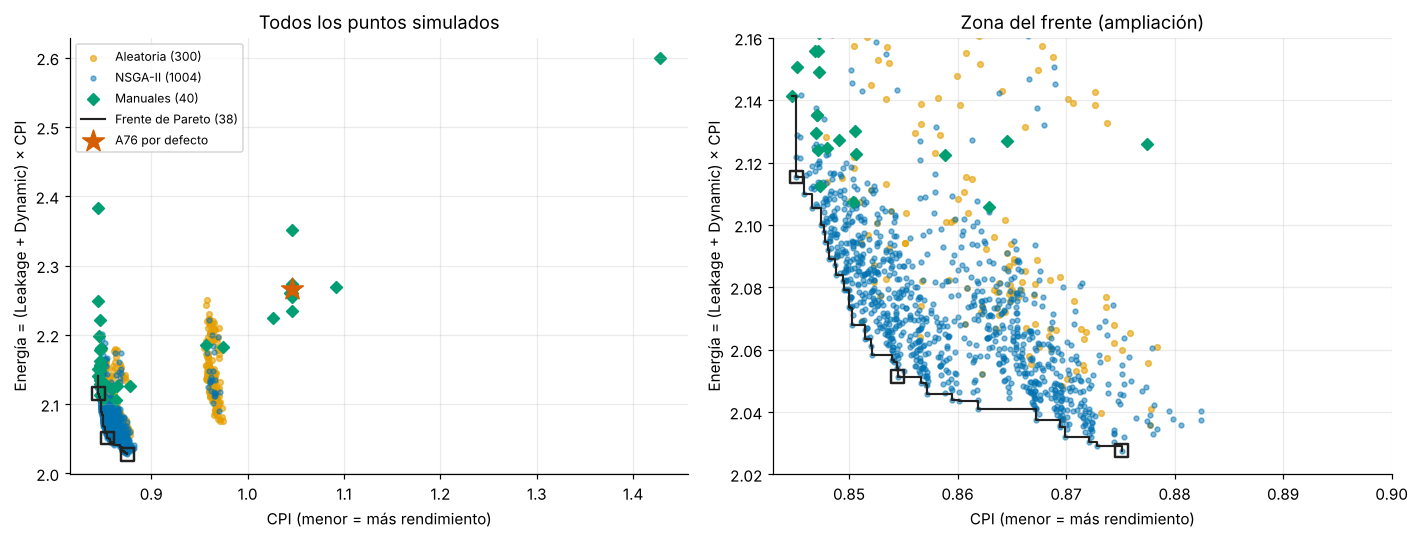

In [12]:
mejor_cpi, mejor_en, mejor_edp = [nsga.loc[nsga[c].idxmin()] for c in ("cpi", "energy", "edp")]
frente = pareto(todo)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, zoom in zip(ax, (False, True)):
    a.scatter(aleat.cpi, aleat.energy, s=14, c=NARANJA, alpha=.6, label=f"Aleatoria ({len(aleat)})")
    a.scatter(nsga.cpi, nsga.energy, s=10, c=AZUL, alpha=.5, label=f"NSGA-II ({len(nsga)})")
    a.scatter(manual.cpi, manual.energy, s=30, c=VERDE, marker="D", label=f"Manuales ({len(manual)})")
    f = frente.sort_values("cpi"); a.step(f.cpi, f.energy, where="post", color=NEGRO, lw=1.4, label=f"Frente de Pareto ({len(f)})")
    a.scatter(BASE.cpi, BASE.energy, marker="*", s=220, c=ROJO, label="A76 por defecto")
    for r in (mejor_cpi, mejor_en, mejor_edp):
        a.scatter(r.cpi, r.energy, marker="s", s=70, facecolor="none", edgecolor=NEGRO, lw=1.6)
    a.set_xlabel("CPI (menor = más rendimiento)"); a.set_ylabel("Energía = (Leakage + Dynamic) × CPI")
ax[0].set_title("Todos los puntos simulados"); ax[0].legend(fontsize=8)
ax[1].set_xlim(0.843, 0.90); ax[1].set_ylim(2.02, 2.16); ax[1].set_title("Zona del frente (ampliación)")
plt.tight_layout(); plt.savefig("figuras/fig4_plano_cpi_energia.png", dpi=150); plt.show()

**Figura 4.** Rendimiento (CPI) frente a energía de las 1330 simulaciones. La línea negra es el frente de Pareto global; los cuadrados marcan las tres mejores configuraciones (sección 9).

**Análisis.** La nube azul (NSGA-II) se concentra en la zona "mejor" (abajo a la izquierda), mientras que la aleatoria se reparte por todo el espacio.

El A76 por defecto (estrella roja) queda lejos del frente: la IQ de 16 entradas es la limitación dominante. El frente de 38 puntos incluye 37 del NSGA-II y 1 manual (L1I de 128 kB, fuera del espacio del DSE); ninguna simulación aleatoria llega al frente.
Todos los puntos del frente tienen ancho 4, `issue_width` 4 (28) o 3 (9), IQ 48 (26) o 64 (11) y SQ de 32 entradas (32 de 37); el extremo rápido usa IQ 64, ROB 128 y L2 de 512 kB, y el eficiente usa IQ 48, ROB 64, L1 de 16 kB y L2 de 128 kB.

### 8.3 Relación del EDP con el CPI y la energía y evolución de la exploración

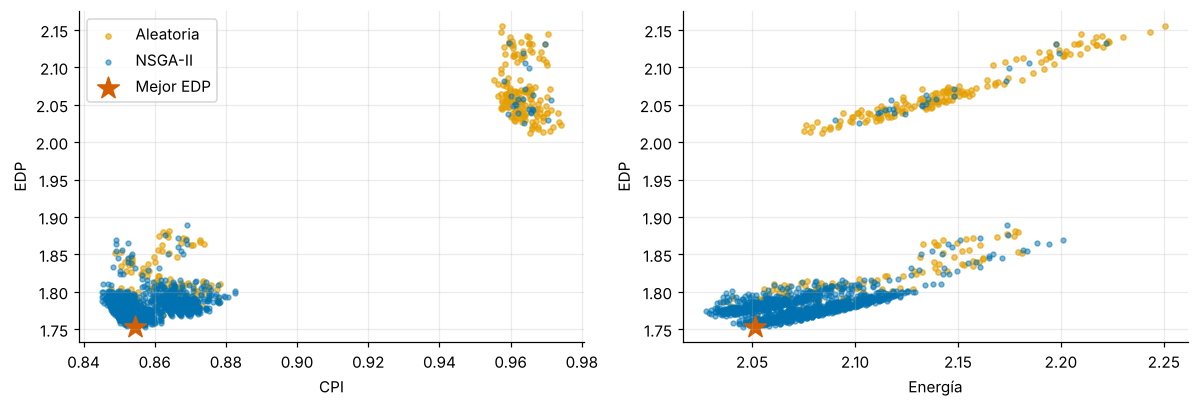

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, x, nombre in zip(ax, ("cpi", "energy"), ("CPI", "Energía")):
    a.scatter(aleat[x], aleat.edp, s=12, c=NARANJA, alpha=.6, label="Aleatoria")
    a.scatter(nsga[x], nsga.edp, s=10, c=AZUL, alpha=.5, label="NSGA-II")
    a.scatter(mejor_edp[x], mejor_edp.edp, marker="*", s=220, c=ROJO, label="Mejor EDP")
    a.set_xlabel(nombre); a.set_ylabel("EDP")
ax[0].legend()
plt.tight_layout(); plt.savefig("figuras/fig5_edp_vs_cpi_energia.png", dpi=150); plt.show()

**Figura 5.** EDP frente a CPI (izquierda) y frente a energía (derecha).

**Análisis.** El EDP = energía × CPI crece con ambas métricas, pero el menor EDP no coincide con el menor CPI ni con la menor energía: la mejor configuración por EDP (estrella) queda en un punto intermedio del frente, con un CPI de 0,854 (el mínimo es 0,845) y una energía de 2,051 (el mínimo es 2,028).
Por eso el EDP sirve para elegir un equilibrio, mientras que CPI y energía se optimizaron como objetivos separados.

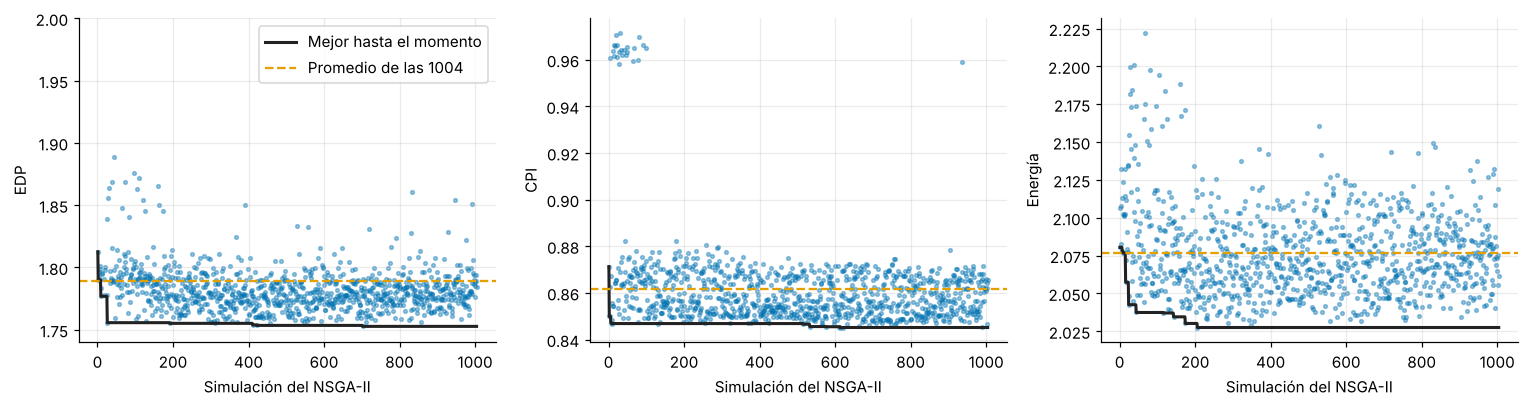

Mejor EDP en la generación 1 (50 simulaciones): 1.75570 | mejor EDP final: 1.75273


In [14]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, c, nombre in zip(ax, ("edp", "cpi", "energy"), ("EDP", "CPI", "Energía")):
    a.scatter(nsga.index + 1, nsga[c], s=6, c=AZUL, alpha=.4)
    a.plot(nsga.index + 1, nsga[c].cummin(), color=NEGRO, lw=2, label="Mejor hasta el momento")
    a.axhline(nsga[c].mean(), color=NARANJA, ls="--", label="Promedio de las 1004")
    a.set_xlabel("Simulación del NSGA-II"); a.set_ylabel(nombre)
ax[0].legend(); ax[0].set_ylim(1.74, 2.0)
plt.tight_layout(); plt.savefig("figuras/fig6_evolucion.png", dpi=150); plt.show()
print(f"Mejor EDP en la generación 1 (50 simulaciones): {nsga[nsga.gen == 1].edp.min():.5f} | mejor EDP final: {nsga.edp.min():.5f}")

**Figura 6.** Evolución del EDP, el CPI y la energía a lo largo de las 1004 simulaciones del NSGA-II. Cada punto es una simulación; la línea negra es el mejor valor hasta ese momento y la naranja el promedio.

**Análisis.** La exploración converge rápido: la primera generación (50 simulaciones, que incluye las semillas) ya alcanza un EDP de 1,7557, a solo 0,17 % del mejor final (1,7527). Las generaciones siguientes concentran las muestras en la zona buena
(el promedio del EDP de las 1004 es 1,789, cerca del mejor)

### 8.4 Efecto de cada parámetro: media y desviación estándar
Las 300 configuraciones aleatorias son una muestra uniforme del espacio, por lo que su media por valor de cada parámetro no está sesgada por la búsqueda (a diferencia del NSGA-II, que muestrea más donde el EDP es bueno).
Las barras indican la **desviación estándar** del EDP entre las configuraciones que comparten ese valor: es la dispersión debida a todas las demás variables. Como el ancho divide en dos ancho 3 y ancho 4, los demás parámetros se muestran solo con las configuraciones de ancho 4.

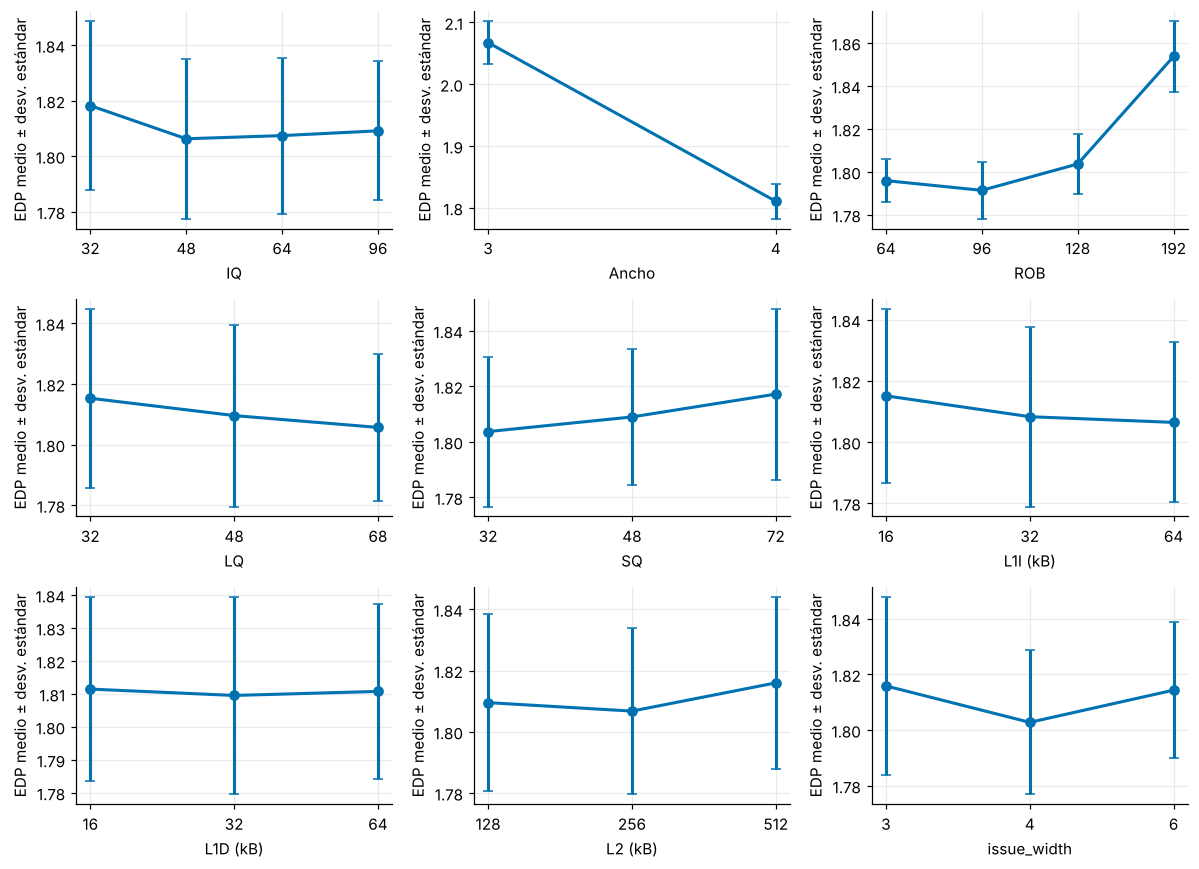

In [15]:
nombres = {"iq_entries": "IQ", "width": "Ancho", "rob_entries": "ROB", "lq_entries": "LQ", "sq_entries": "SQ",
           "l1i_kb": "L1I (kB)", "l1d_kb": "L1D (kB)", "l2_kb": "L2 (kB)", "issue_width": "issue_width"}
fig, axs = plt.subplots(3, 3, figsize=(11, 8))
for ax, k in zip(axs.ravel(), KEYS):
    datos = aleat if k == "width" else aleat[aleat.width == 4]
    g = datos.groupby(k).edp.agg(["mean", "std"])
    ax.errorbar(g.index.astype(str), g["mean"], yerr=g["std"], fmt="o-", color=AZUL, capsize=3, lw=2)
    ax.set_xlabel(nombres[k]); ax.set_ylabel("EDP medio ± desv. estándar")
plt.tight_layout(); plt.savefig("figuras/fig7_efecto_parametros.png", dpi=150); plt.show()

**Figura 7.** EDP medio ± desviación estándar para cada valor de cada parámetro (muestra aleatoria).

**Análisis.**
- **El ancho es lo que más pesa:** EDP medio de 2,067 con ancho 3 frente a 1,811 con ancho 4, una diferencia (0,26) muy superior a la dispersión dentro de cada grupo.
- **Entre los demás, solo el ROB se distingue:** con 192 entradas el EDP medio sube a 1,854, frente a 1,79–1,80 con 64, 96 o 128 entradas.
- **El resto de parámetros (IQ entre 32 y 96, colas, cachés e `issue_width`) cambia el EDP medio menos de 0,013, del orden de la dispersión (≈ 0,03):** son ajustes finos que no se pueden separar individualmente con esta muestra.

### 8.5 Distribución estadística del EDP

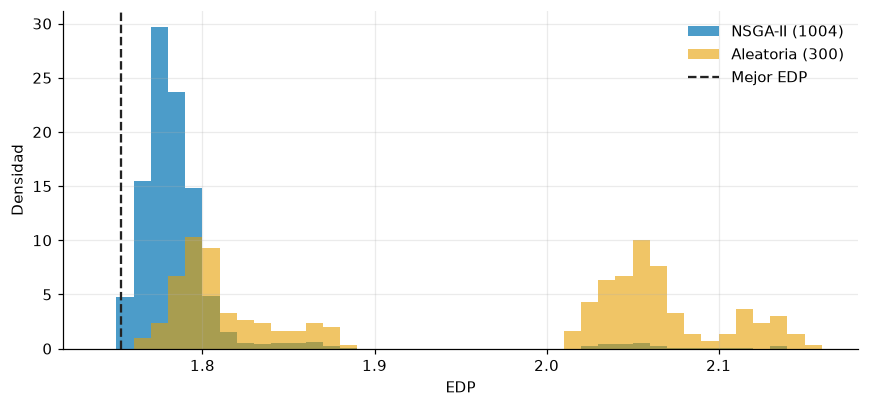

In [124]:
fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.linspace(1.74, 2.16, 43)
ax.hist(nsga.edp, bins=bins, density=True, color=AZUL, alpha=.7, label=f"NSGA-II ({len(nsga)})")
ax.hist(aleat.edp, bins=bins, density=True, color=NARANJA, alpha=.6, label=f"Aleatoria ({len(aleat)})")
ax.axvline(mejor_edp.edp, color=NEGRO, ls="--", label="Mejor EDP")
ax.set_xlabel("EDP"); ax.set_ylabel("Densidad"); ax.legend()
plt.tight_layout(); plt.savefig("figuras/fig8_distribucion_edp.png", dpi=150); plt.show()

**Figura 8.** Distribución del EDP en las simulaciones del NSGA-II y en las aleatorias (histograma normalizado).

**Análisis.** El NSGA-II concentra sus simulaciones en la zona buena: el 88 % tiene un EDP por debajo de 1,80, con media 1,789 y desviación estándar 0,047. La búsqueda aleatoria tiene una distribución con dos grupos (diseños de ancho 4 en torno a 1,81 y de ancho 3 en torno a 2,07):
media 1,949, desviación estándar 0,132 y solo el 20 % de las configuraciones por debajo de 1,80. El histograma muestra cuánto del espacio es "malo" por una sola decisión (el ancho) y por qué una búsqueda guiada rinde más que una uniforme.

### 8.6 NSGA-II frente a búsqueda aleatoria
Se comparan con 300 sims. El NSGA-II arranca con 6 semillas de los experimentos manuales, que ya habían acotado el espacio, el aleatorio arranca sin nada.

In [125]:
N = 300
ns, al = nsga.head(N), aleat.head(N)
ref = (unicas.cpi.max(), unicas.energy.max())                 # punto de referencia común para el hipervolumen
def resumen(df):
    return {"Mejor EDP": df.edp.min(), "Mejor CPI": df.cpi.min(), "Mejor energía": df.energy.min(),
            "Puntos en el frente": len(pareto(df)), "Hipervolumen": hipervolumen(df, ref),
            "EDP medio": df.edp.mean()}
pd.DataFrame({"NSGA-II (300)": resumen(ns), "Aleatoria (300)": resumen(al), "NSGA-II (1004)": resumen(nsga)}).round(5)

,NSGA-II (300),Aleatoria (300),NSGA-II (1004)
Mejor EDP,1.75516,1.76126,1.75273
Mejor CPI,0.84685,0.84786,0.84515
Mejor energía,2.02751,2.03586,2.02751
Puntos en el frente,28.00000,9.00000,37.00000
Hipervolumen,0.02770,0.02644,0.02803
EDP medio,1.81033,1.94914,1.78899


**Tabla 10.** Comparación NSGA-II y búsqueda aleatoria.

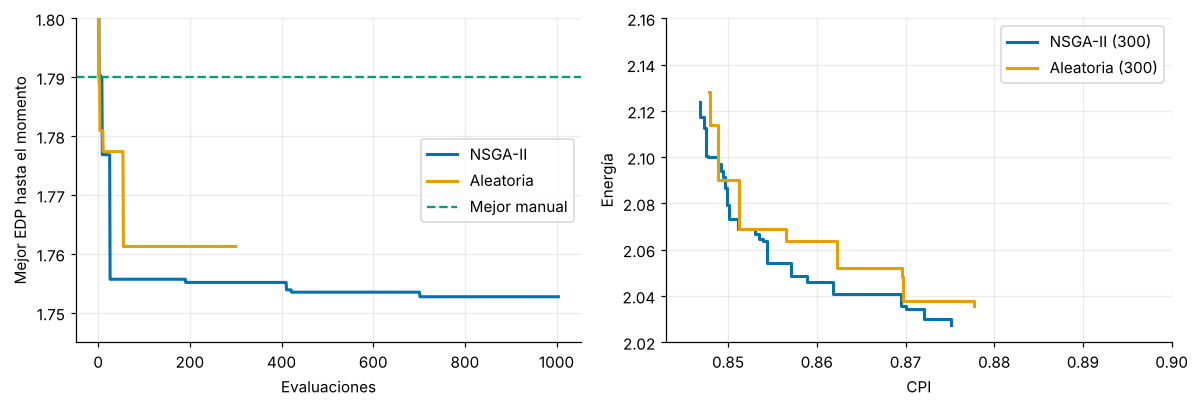

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(nsga.index + 1, nsga.edp.cummin(), color=AZUL, lw=2, label="NSGA-II")
ax[0].plot(aleat.index + 1, aleat.edp.cummin(), color=NARANJA, lw=2, label="Aleatoria")
ax[0].axhline(manual.edp.min(), color=VERDE, ls="--", label="Mejor manual")
ax[0].set_ylim(1.745, 1.80); ax[0].set_xlabel("Evaluaciones"); ax[0].set_ylabel("Mejor EDP hasta el momento"); ax[0].legend()
for df, color, nombre in ((ns, AZUL, "NSGA-II (300)"), (al, NARANJA, "Aleatoria (300)")):
    f = pareto(df).sort_values("cpi"); ax[1].step(f.cpi, f.energy, where="post", color=color, lw=2, label=nombre)
ax[1].set_xlim(0.843, 0.90); ax[1].set_ylim(2.02, 2.16); ax[1].set_xlabel("CPI"); ax[1].set_ylabel("Energía"); ax[1].legend()
plt.tight_layout(); plt.savefig("figuras/fig9_nsga_vs_aleatoria.png", dpi=150); plt.show()

**Figura 9.** Convergencia del mejor EDP (izquierda) y frentes de Pareto con 300 evaluaciones (derecha).

**Análisis.** En el *mejor punto* la diferencia es pequeña: con 300 evaluaciones el mejor EDP aleatorio queda a 0,35 % del NSGA-II, porque el espacio ya estaba muy acotado.
En la *calidad del frente* el NSGA-II gana: 28 puntos no dominados frente a 9, mayor hipervolumen y 41 configuraciones a menos de 1 % del mejor EDP frente a 3. El NSGA-II converge pronto (con unas 250 simulaciones alcanza el 98,7 % del hipervolumen final)

## 9. Las tres mejores configuraciones

In [19]:
mejores = pd.DataFrame([mejor_cpi, mejor_en, mejor_edp], index=["Mejor rendimiento (CPI)", "Mejor energía", "Mejor EDP"])
display(mejores[KEYS + ["cpi", "ipc", "power_w", "energy", "edp", "area_mm2"]].round(5))
cambio = pd.DataFrame({m: 100 * (mejores[c] / BASE[c] - 1) for m, c in
                       (("ΔCPI %", "cpi"), ("ΔPotencia %", "power_w"), ("ΔEnergía %", "energy"), ("ΔEDP %", "edp"), ("ΔÁrea %", "area_mm2"))})
print(f"Variación respecto al A76 por defecto (CPI {BASE.cpi:.6f}, energía {BASE.energy:.5f}, EDP {BASE.edp:.5f}):")
display(cambio.round(2))

,iq_entries,width,rob_entries,lq_entries,sq_entries,l1i_kb,l1d_kb,l2_kb,issue_width,cpi,ipc,power_w,energy,edp,area_mm2
Mejor rendimiento (CPI),64,4,128,68,48,32,64,512,4,0.84515,1.18322,2.50295,2.11538,1.78782,35.3661
Mejor energía,48,4,64,32,32,16,16,128,3,0.87512,1.14270,2.31682,2.02751,1.77432,34.0874
Mejor EDP,48,4,96,48,32,32,32,128,4,0.85446,1.17032,2.40064,2.05126,1.75273,34.4147


Variación respecto al A76 por defecto (CPI 1.045577, energía 2.26681, EDP 2.37013):


,ΔCPI %,ΔPotencia %,ΔEnergía %,ΔEDP %,ΔÁrea %
Mejor rendimiento (CPI),-19.17,15.45,-6.68,-24.57,-0.48
Mejor energía,-16.30,6.86,-10.56,-25.14,-4.08
Mejor EDP,-18.28,10.73,-9.51,-26.05,-3.16


**Tabla 11.** Mejores configuraciones del DSE y su variación respecto al A76 por defecto.


## 10. Velocidad de simulación

La **Tabla 12** da el tiempo de una simulación; la **Tabla 13** el total de cada exploración. `gem5` es el tiempo de reloj del simulador;
`McPAT` incluye la conversión de `stats.txt` al formato de McPAT. 

**Tabla 12.** Una simulación, medida en el PC personal.

| Medida | Valor |
|---|---|
| gem5, sola | 593 s |
| McPAT (conversión + potencia) | 21 s |
| Flujo completo | 617 s (≈ 5,8 simulaciones por hora en serie) |
| gem5 con 6 simulaciones a la vez | 714 s de media |

In [21]:
filas = {}
for nombre, df in (("NSGA-II", nsga), ("Aleatoria", todo[todo.source == "random"])):
    dur = df.gem5_wall_s + df.mcpat_s                            # duración de cada simulación (s)
    fin = pd.to_datetime(df.timestamp)
    real_h = ((fin.max() - fin.min()).total_seconds() + dur.mean()) / 3600
    filas[nombre] = {"Simulaciones": len(df), "gem5, media (s)": df.gem5_wall_s.mean(), "gem5, mín–máx (s)": f"{df.gem5_wall_s.min():.0f}–{df.gem5_wall_s.max():.0f}",
                     "McPAT, media (s)": df.mcpat_s.mean(), "McPAT (% del total)": 100 * df.mcpat_s.sum() / dur.sum(),
                     "Tiempo de CPU (h)": dur.sum() / 3600, "Tiempo real (h)": real_h, "Simulaciones por hora": len(df) / real_h,
                     "Aceleración": dur.sum() / 3600 / real_h}
pd.DataFrame(filas).round(2)

,NSGA-II,Aleatoria
Simulaciones,1004,286
"gem5, media (s)",1102.247311,1081.007692
"gem5, mín–máx (s)",700–1323,736–1318
"McPAT, media (s)",32.769522,32.303497
McPAT (% del total),2.88714,2.901569
Tiempo de CPU (h),316.543583,88.446389
Tiempo real (h),34.405282,9.668142
Simulaciones por hora,29.181565,29.581692
Aceleración,9.200436,9.14823


**Tabla 13.** Velocidad en el DSE (10 simulaciones en paralelo, estación de trabajo).

**Análisis.** El tiempo toma más por gem5: McPAT con la conversión es cerca del 3 % de cada simulación. Con 10 workers en 6 núcleos físicos se logra una aceleración de ≈ 9× respecto a la ejecución en serie y ≈ 29 simulaciones por hora,
apenas un 8 % más que con 6 workers en el pc personal (los hilos adicionales ayudan poco y cada simulación se vuelve más lenta).

## 11. Conclusiones

### 11.1 Conclusiones
- **Rendimiento y energía compiten.** El frente de Pareto va de una configuración rápida (CPI 0,845, energía 2,115) a una eficiente (CPI 0,875, energía 2,028); el EDP permite elegir un punto intermedio (CPI 0,854, energía 2,051).
- **Mejora sobre el A76 por defecto:** la mejor configuración por EDP reduce el EDP un 26,05 %, con CPI 18,28 % menor, energía 9,51 % menor y área 3,16 % menor. La causa principal es ampliar la cola de instrucciones de 16 a 48–64 entradas; el resto son ajustes finos de ROB, colas, `issue_width` y cachés.
- **Estrategia.** Las simulaciones manuales acotaron el espacio; el NSGA-II encontró un frente denso de 37 puntos y superó a la búsqueda aleatoria sobre todo en la calidad del frente.
- **Alcance.** Se exploraron 1330 simulaciones de un espacio de 23 328 combinaciones (5,7 %) con una sola aplicación, `mp3_enc`.

### 11.2 Dificultades

1. **El flujo completo es lo más difícil de entender al empezar.** Cada simulación encadena tres herramientas (gem5, el conversor y McPAT) y genera varios archivos intermedios. Hasta ver una simulación de principio a fin (de `stats.txt` y `config.json` a `config.xml`, `potencia.txt` y una fila de `results.csv`) no estaba claro qué dato salía de dónde. Documentar ese flujo (sección 7.1) y fijar una única forma de lanzar gem5 fue lo que hizo reproducible el resto del trabajo.

2. **Las simulaciones manuales sirven para decidir, no para explorar.** Las 40 simulaciones manuales son solo el 3 % del total, pero son las que permitieron saber que la cola de instrucciones (IQ) era el cuello de botella, qué parámetros ve McPAT y qué rangos valía la pena explorar. También aportaron las semillas del NSGA-II. Sin ese trabajo previo, las mil simulaciones automáticas habrían explorado un espacio mucho más grande.

6. **Comparar con una búsqueda aleatoria da perspectiva.** El NSGA-II supera a la búsqueda aleatoria, pero en el mejor punto solo por 0,35 % del EDP; su ventaja real está en la calidad del frente (28 puntos frente a 9). La comparación no es del todo pareja, porque el NSGA-II partió de semillas obtenidas a mano.


## 12. Resultados y repositorio

Todos los resultados, los datos crudos y las notas de trabajo están en este repositorio git.

**Estructura del repositorio git:**
```
Microarchitecture-sims/
├── README.md
├── Lab1_DSE_CortexA76.ipynb   # este notebook
├── dse.py                     # motor del DSE (sección 7)
├── config/                    # espacio.csv, semillas.csv y manuales.txt (lo que lee dse.py)
├── scripts/sim.sh             # una simulación a mano (sección 7)
├── scripts/gem5toMcPAT_cortexA76.py  # conversor gem5 → McPAT (sección 7.1)
├── results/                   # results.csv, random_log.csv, nsga.log, maquina.txt, results_check.csv
├── crudos/                    # dse/ (estación de trabajo) y manuales/ (PC personal)
├── notas/                     # notas de cada fase
└── figuras/                   # figuras de este notebook
```
**Para reproducir el análisis:** instalar `numpy`, `pandas` y `matplotlib`, abrir el notebook junto a `results/` y ejecutar todo con `RUN_SIMS = False`.
**Para relanzar el DSE:** instalar gem5 v25.0.0.1, McPAT y `pymoo`, y seguir el uso de la sección 7.

## 13. Declaración de uso de IA

Para este trabajo se usó un asistente de inteligencia artificial (Claude) como herramienta de apoyo. Su uso se declara a continuación.

**Dónde se usó:**
- **Código de apoyo:** Depuración de `dse.py` y de las celdas de análisis y gráficas del notebook (`pandas` y `matplotlib`).
- **Análisis de datos:** cálculo del frente de Pareto, hipervolumen y estadísticas por parámetro

## 14. Referencias

[1] Binkert, N. et al. (2011). The gem5 simulator. *ACM SIGARCH Computer Architecture News*, 39(2), 1–7.
[2] Li, S. et al. (2009). McPAT: An integrated power, area, and timing modeling framework for multicore and manycore architectures. *Proc. 42nd IEEE/ACM International Symposium on Microarchitecture (MICRO-42)*, 469–480.
[3] Deb, K., Pratap, A., Agarwal, S., Meyarivan, T. (2002). A fast and elitist multiobjective genetic algorithm: NSGA-II. *IEEE Transactions on Evolutionary Computation*, 6(2), 182–197.
[4] Blank, J., Deb, K. (2020). pymoo: Multi-objective optimization in Python. *IEEE Access*, 8, 89497–89509.
[5] Hennessy, J. L., Patterson, D. A. (2019). *Computer Architecture: A Quantitative Approach* (6.ª ed.). Morgan Kaufmann.